# Pipeline: SED Modelling of MG3 J163554+3629

**Author:** Mirza Laraib Mustafa  
**Supervisor:** Prof. Eugenio Bottacini  
**Co-Supervisor:** Dr. Andrea Tramacere  
**Object:** MG3 J163554+3629 — High-redshift FSRQ blazar (z = 3.648)  
**Purpose:** Master pipeline. Run this notebook first — it builds and saves the prefit model that all other notebooks depend on.

**Output files saved to `../results/models/`:**
- `prefit_model.pkl` — full composite model (jet + EBL), ready for fitting
- `sed_data_unbinned.pkl` — processed SED data (no binning)
- `sed_data_binned.pkl` — processed SED data (binned, bin_width=0.15)

---
## Steps
| Step | What it does |
|------|--------------|
| 0 | Imports and version check |
| 1 | Load raw SED data from `../data/SED.txt` |
| 2 | Add systematics and flag upper limits |
| 3 | Bin the data (compare binned vs unbinned) |
| 4 | SED shape characterisation (sync + IC peak finding) |
| 5 | Physical prefit using ObsConstrain |
| 6 | Add opening angle geometry + EBL absorption |
| 7 | Save model and data for downstream notebooks |

In [41]:
import jetset
print('JetSeT version:', jetset.__version__)

import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
import dill
%matplotlib inline

from jetset.data_loader import Data, ObsData
from jetset.sed_shaper import SEDShape
from jetset.jet_model import Jet
from jetset.obs_constrain import ObsConstrain
from jetset.model_manager import FitModel
from jetset.template_2Dmodel import EBLAbsorptionTemplate

import os
os.makedirs('../results/models', exist_ok=True)
os.makedirs('../results/plots',  exist_ok=True)
print('Output folders ready.')

JetSeT version: 1.3.0
Output folders ready.


---
## Step 1 — Load raw SED data

The file `SED.txt` has three columns: **frequency (Hz)**, **νFν flux (erg cm⁻² s⁻¹)**, **flux error** (0 = upper limit).
We remove the spurious Fermi point at 1.709×10²² Hz and create two independent ObsData objects.

Data points loaded: 45
Frequency range:    1.40e+09 — 7.65e+25 Hz


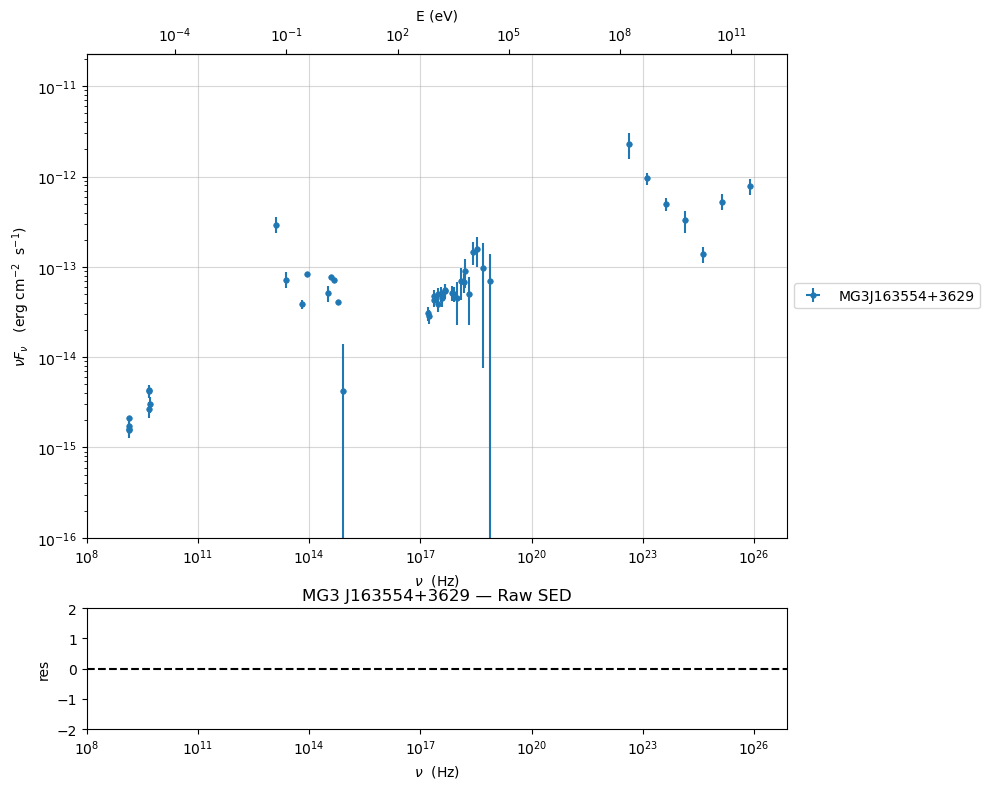

In [42]:
d = np.genfromtxt('../data/SED.txt')
d = d[d[:, 0] != 1.709E22]

print(f'Data points loaded: {d.shape[0]}')
print(f'Frequency range:    {d[:,0].min():.2e} — {d[:,0].max():.2e} Hz')

data = Data(n_rows=d.shape[0])
data.set_field('x',  d[:, 0])
data.set_field('y',  d[:, 1])
data.set_field('dy', d[:, 2])

data.set_meta_data('z',          3.647763)
data.set_meta_data('UL_CL',      0.95)
data.set_meta_data('restframe',  'obs')
data.set_meta_data('data_scale', 'lin-lin')
data.set_meta_data('obj_name',   'MG3J163554+3629')

raw_data = ObsData(data_table=data)
sed_data = ObsData(data_table=data)

myPlot = raw_data.plot_sed()
myPlot.setlim(y_min=1E-16, x_min=1E8)
plt.title('MG3 J163554+3629 — Raw SED')
plt.show()

---
## Step 2 — Add systematics and flag upper limits

**Why add systematics?** Multi-wavelength data come from many telescopes with different calibration uncertainties. We add a **15% floor** across all frequencies.

**Why flag upper limits?** Points with zero error are non-detections — the model is only penalised if it predicts more flux than the upper limit.

In [43]:
sed_data.filter_data_set('-1', exclude=True)
sed_data.add_systematics(0.15, [10.**6, 10.**29])

UL_freq = [
    1.324e25,   # gamma-ray (Fermi)
    7.646e25,   # gamma-ray (Fermi)
    4.188e24,   # gamma-ray (Fermi)
    4.188e22,   # X-ray upper limit
    2.417e13,   # sub-mm
    1.318e13,   # sub-mm
]
for freq in UL_freq:
    mask = np.isclose(sed_data.table['nu_data'], freq, rtol=0.05)
    sed_data.table['UL'][mask] = True

print(f'Upper limits flagged: {sed_data.table["UL"].sum()}')
print(f'Total points:         {len(sed_data.table)}')

---> excluding  data_set/s ['-1']
filter -1 45
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=45
Upper limits flagged: 6
Total points:         45


---
## Step 3 — Binning

**Why bin?** Groups nearby points within 0.15 dex in frequency. Reduces noise, speeds up fitting, avoids over-weighting dense regions.
We keep both versions — downstream notebooks can choose which to use.

---> excluding  data_set/s ['-1']
filter -1 45
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=45
---> excluding  data_set/s ['-1']
filter -1 45
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=45

***  binning data  ***
---> N bins= 113
---> bin_widht= 0.15

Unbinned: 45 points
Binned:   28 points


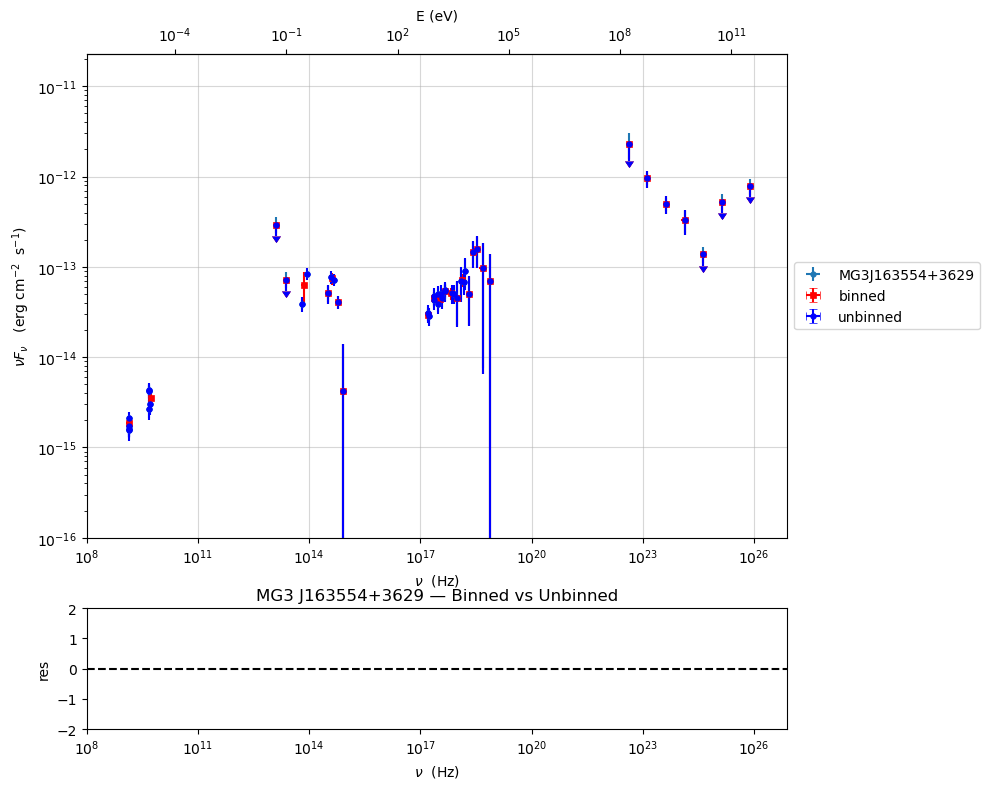

In [44]:
# --- UNBINNED ---
sed_data_unbinned = ObsData(data_table=data)
sed_data_unbinned.filter_data_set('-1', exclude=True)
sed_data_unbinned.add_systematics(0.15, [10.**6, 10.**29])
for freq in UL_freq:
    mask = np.isclose(sed_data_unbinned.table['nu_data'], freq, rtol=0.05)
    sed_data_unbinned.table['UL'][mask] = True

# --- BINNED ---
sed_data_binned = ObsData(data_table=data)
sed_data_binned.filter_data_set('-1', exclude=True)
sed_data_binned.group_data(bin_width=0.15)
sed_data_binned.add_systematics(0.15, [10.**6, 10.**29])
for freq in UL_freq:
    mask = np.isclose(sed_data_binned.table['nu_data'], freq, rtol=0.05)
    sed_data_binned.table['UL'][mask] = True

print(f'Unbinned: {len(sed_data_unbinned.table)} points')
print(f'Binned:   {len(sed_data_binned.table)} points')

myPlot2 = raw_data.plot_sed()
myPlot2.add_data_plot(sed_data_binned,   label='binned',   color='red',  fmt='s', ms=5, mew=0.5)
myPlot2.add_data_plot(sed_data_unbinned, label='unbinned', color='blue', fmt='o', ms=4)
myPlot2.setlim(y_min=1E-16, x_min=1E8)
plt.title('MG3 J163554+3629 — Binned vs Unbinned')
plt.show()

sed_data = sed_data_unbinned

---
## Step 4 — SED shape characterisation

Fits phenomenological functions to the two SED humps:
- **Synchrotron peak** (radio → UV): log-parabola in 10⁹–10¹⁶ Hz
- **IC peak** (X-ray → gamma): power law in 10¹⁶–10²⁶ Hz

Peak frequencies and luminosities are used by ObsConstrain in Step 5.


*** evaluating spectral indices for data ***


*** Log-Polynomial fitting of the synchrotron component ***
---> first blind fit run,  fit range: [9, 16]
---> class:  ISP

--> class:  LSP




model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
LogParabolaEp,b,-8.256408e-02,-8.256408e-02,2.584721e-02,--,-6.224913e-02,-1.000000e+01,0.000000e+00,False
LogParabolaEp,Ep,1.330904e+01,1.330904e+01,5.717990e-01,--,1.413585e+01,0.000000e+00,3.000000e+01,False
LogParabolaEp,Sp,-1.333490e+01,-1.333490e+01,7.469589e-02,--,-1.320459e+01,-3.000000e+01,0.000000e+00,False
BBB,nuFnu_p_BBB,-1.338371e+01,-1.338371e+01,1.806069e-01,--,-1.320459e+01,-1.520459e+01,-1.120459e+01,False
BBB,nu_scale,4.312914e-02,4.312914e-02,6.422704e-03,--,0.000000e+00,-5.000000e-01,5.000000e-01,False


---> sync       nu_p=+1.330904e+01 (err=+5.717990e-01)  nuFnu_p=-1.333490e+01 (err=+7.469589e-02) curv.=-8.256408e-02 (err=+2.584721e-02)


*** Log-Polynomial fitting of the IC component ***
---> fit range: [16, 26]
---> LogCubic fit
====> simplex
====> migrad
====> simplex
====> migrad
====> simplex
====> migrad




model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
LogCubic,b,-1.362857e-01,-1.362857e-01,2.137025e-02,--,-1.000000e+00,-1.000000e+01,0.000000e+00,False
LogCubic,c,-1.412340e-02,-1.412340e-02,3.894639e-03,--,-1.000000e+00,-1.000000e+01,1.000000e+01,False
LogCubic,Ep,2.206163e+01,2.206163e+01,1.234883e-01,--,2.324243e+01,0.000000e+00,3.000000e+01,False
LogCubic,Sp,-1.186960e+01,-1.186960e+01,1.075056e-01,--,-1.000000e+01,-3.000000e+01,0.000000e+00,False


---> IC         nu_p=+2.206163e+01 (err=+1.234883e-01)  nuFnu_p=-1.186960e+01 (err=+1.075056e-01) curv.=-1.362857e-01 (err=+2.137025e-02)



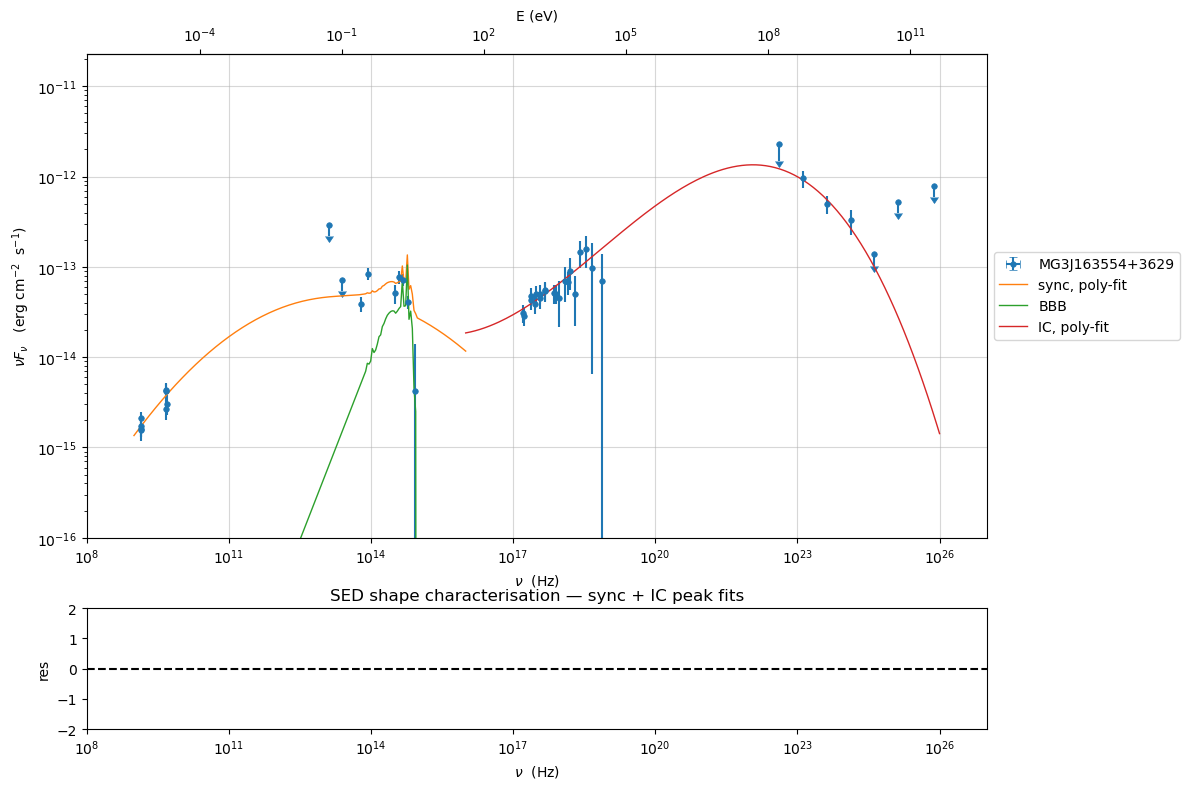

>>> Checkpoint: SEDShape complete.


In [45]:
my_shape = SEDShape(sed_data)
my_shape.eval_indices(silent=True)

my_shape.sync_fit(
    check_BBB_template=True,
    check_host_gal_template=False,
    use_log_par=True,
    minimizer='lsb',
    fit_range=[9, 16],
    silent=True
)

my_shape.IC_fit(fit_range=[16, 26], minimizer='minuit', silent=True)

p = my_shape.plot_shape_fit()
p.setlim(y_min=1E-16)
plt.title('SED shape characterisation — sync + IC peak fits')
plt.show()

print('>>> Checkpoint: SEDShape complete.')

---
## Step 5 — Physical prefit with ObsConstrain

Uses SED shape results to derive physically self-consistent starting values.
Model: SSC + EC (BLR + Disk + DT) with broken power law electron distribution.
Central engine parameters overridden with values from Sánchez Zaballa (2025).


***  constrains parameters from observable ***

===> setting C threads to 8
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,R,region_size,cm,3.721835e+16,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H,region_position,cm,1.500000e+18,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,7.620413e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,theta,jet-viewing-angle,deg,3.000000e+00,0.000000e+00,9.000000e+01,False,False
jet_leptonic,BulkFactor,jet-bulk-factor,lorentz-factor*,1.850000e+01,1.000000e+00,1.000000e+05,False,False
jet_leptonic,z_cosm,redshift,,3.647763e+00,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.937958e+01,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,2.686264e+04,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.717180e+03,0.000000e+00,--,False,False


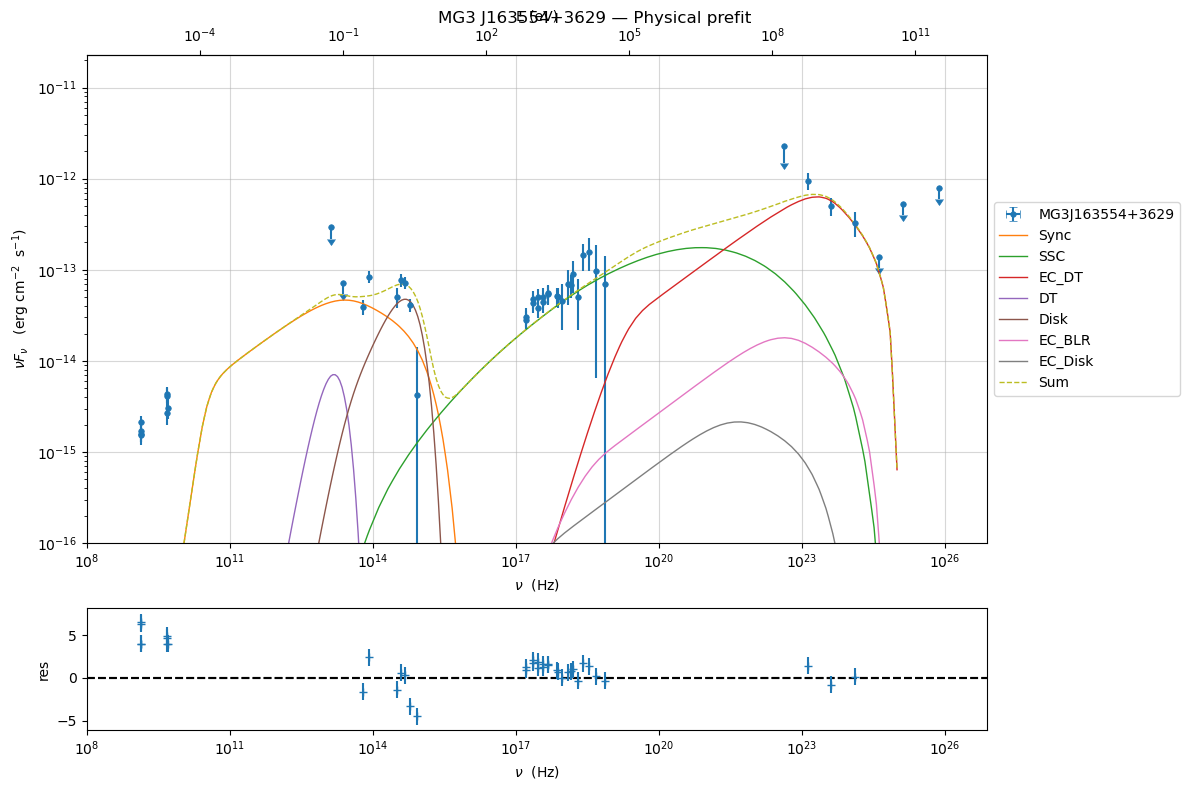

>>> Checkpoint: Prefit complete.
    Beaming factor δ : 19.097
    B                : 0.0762 G
    R_H              : 1.500e+18 cm


In [46]:
sed_obspar = ObsConstrain(
    theta=3,
    bulk_factor=18.5,
    B_range=[0.02, 0.08],
    distr_e='bkn',
    t_var_sec=7*86400,
    nu_cut_IR=1E9,
    SEDShape=my_shape
)

prefit_jet = sed_obspar.constrain_SSC_EC_model(
    electron_distribution_log_values=False,
    EC_components_list=['EC_DT', 'EC_BLR', 'EC_Disk'],
    R_H=1.5E18,
    disk_type='MultiBB',
    silent=True
)

prefit_jet.set_par('L_Disk',   val=1.3817e46)
prefit_jet.set_par('M_BH',     val=1.4677e9)
prefit_jet.set_par('accr_eff', val=0.09)
prefit_jet.set_par('T_DT',     val=881.9)
prefit_jet.set_par('tau_DT',   val=0.1)
prefit_jet.set_par('tau_BLR',  val=0.1)

prefit_jet.eval()
p = prefit_jet.plot_model(sed_data=sed_data)
p.add_residual_plot(prefit_jet, sed_data)
p.setlim(y_min=1E-16, x_min=1E8)
plt.suptitle('MG3 J163554+3629 — Physical prefit')
plt.show()

print(f'>>> Checkpoint: Prefit complete.')
print(f'    Beaming factor δ : {prefit_jet.get_beaming():.3f}')
print(f'    B                : {prefit_jet.parameters.B.val:.4f} G')
print(f'    R_H              : {prefit_jet.parameters.R_H.val:.3e} cm')

---
## Step 6 — Opening angle geometry + EBL absorption

**Geometry:** R = R_H × tan(θ_open). We set theta_open=3° and keep R_H=1.5e18 cm fixed.
We do NOT recompute R_H from target_R — this was causing R_H to be saved with the wrong value.

**EBL:** Franceschini et al. (2008), linked to jet redshift.

adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open)) * R_H
theta_open : 3 deg
R_H        : 1.500e+18 cm
R          : 7.861e+16 cm  (should be ~7.85e16)
adding par: z_cosm to  z_cosm


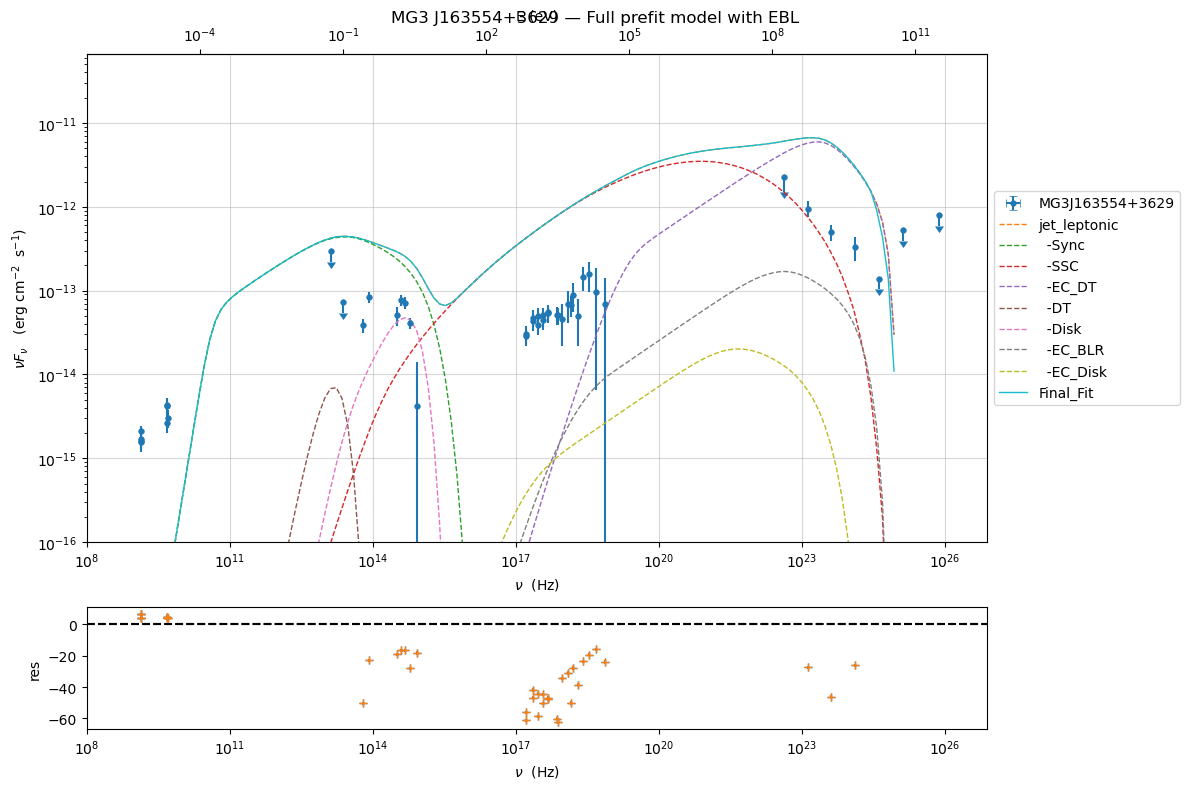

>>> Model assembled at z = 3.647763

--------------------------------------------------------------------------------
Composite model description
--------------------------------------------------------------------------------
name: Final_Fit  
type: composite_model  
components models:
 -model name: jet_leptonic model type: jet
 -model name: Franceschini_2008 model type: table2D

--------------------------------------------------------------------------------
individual component description

--------------------------------------------------------------------------------
model description: 
--------------------------------------------------------------------------------
type: Jet
name: jet_leptonic  
geometry: spherical  

electrons distribution:
 type: bkn  
 gamma energy grid size:  201
 gmin grid : 2.937958e+01
 gmax grid : 2.686264e+04
 normalization:  True
 log-values:  False
 ratio of cold protons to relativistic electrons: 1.000000e+00

accretion disk:
 disk Type: MultiBB
 L d

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,"*R(D,theta_open)",region_size,cm,7.861167e+16,1.000000e+03,1.000000e+30,False,True
jet_leptonic,R_H(M),region_position,cm,1.500000e+18,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,7.620413e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,theta,jet-viewing-angle,deg,3.000000e+00,0.000000e+00,9.000000e+01,False,False
jet_leptonic,BulkFactor,jet-bulk-factor,lorentz-factor*,1.850000e+01,1.000000e+00,1.000000e+05,False,False
jet_leptonic,z_cosm(M),redshift,,3.647763e+00,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.937958e+01,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,2.686264e+04,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.717180e+03,0.000000e+00,--,False,False


--------------------------------------------------------------------------------

--------------------------------------------------------------------------------
model description
--------------------------------------------------------------------------------
name: Franceschini_2008  
type: table2D  

--------------------------------------------------------------------------------


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
Franceschini_2008,scale_factor,scale_factor,,1.000000e+00,0.000000e+00,--,False,True
Franceschini_2008,"z_cosm(L,jet_leptonic)",redshift,,--,--,--,False,True


--------------------------------------------------------------------------------
--------------------------------------------------------------------------------


In [47]:
# --- Opening angle dependency ---
# IMPORTANT: We set R_H = 1.5e18 cm FIRST, then add the dependency.
# Do NOT recompute R_H from target_R — that gives a wrong value.
prefit_jet.parameters.R_H.val = 1.5e18

prefit_jet.add_user_par(name='theta_open', val=3, units='deg')
prefit_jet.make_dependent_par(
    par='R',
    depends_on=['R_H', 'theta_open'],
    par_expr='np.tan(np.radians(theta_open)) * R_H'
)

prefit_jet.eval()

# Verify — R should be positive and ~7.85e16
print(f'theta_open : {prefit_jet.parameters.theta_open.val} deg')
print(f'R_H        : {prefit_jet.parameters.R_H.val:.3e} cm')
print(f'R          : {prefit_jet.parameters.R.val:.3e} cm  (should be ~7.85e16)')
assert prefit_jet.parameters.R.val > 0, 'ERROR: R is negative!'

# --- EBL ---
ebl_franceschini = EBLAbsorptionTemplate.from_name('Franceschini_2008')
fit_model = FitModel(jet=prefit_jet, name='Final_Fit')
fit_model.add_component(ebl_franceschini)

fit_model.link_par(
    par_name='z_cosm',
    from_model='Franceschini_2008',
    to_model='jet_leptonic'
)
fit_model.composite_expr = 'jet_leptonic * Franceschini_2008'

fit_model.eval()
p = fit_model.plot_model(sed_data=sed_data)
p.add_residual_plot(fit_model, sed_data)
p.setlim(y_min=1E-16, x_min=1E8)
plt.suptitle('MG3 J163554+3629 — Full prefit model with EBL')
plt.show()

print(f'>>> Model assembled at z = {prefit_jet.parameters.z_cosm.val}')
fit_model.show_model()

---
## Step 7 — Save everything

**Do not skip this cell.** All downstream notebooks load these files.
We verify R_H and R are correct before saving.

In [48]:
# Final verification before saving
print('=== Final verification ===')
print(f'R_H        : {fit_model.jet_leptonic.parameters.R_H.val:.3e} cm')
print(f'R          : {fit_model.jet_leptonic.parameters.R.val:.3e} cm')
print(f'theta_open : {fit_model.jet_leptonic.parameters.theta_open.val} deg')
assert fit_model.jet_leptonic.parameters.R.val > 0, 'ERROR: R is negative — do not save!'
assert fit_model.jet_leptonic.parameters.R_H.val > 1e17, 'ERROR: R_H too small — do not save!'
print('All checks passed. Saving...')

# Save prefit model
dill.dump(fit_model, open('../results/models/prefit_model.pkl', 'wb'))
print('Saved: prefit_model.pkl')

# Save SED data
sed_data_unbinned.save('../results/models/sed_data_unbinned.pkl')
print('Saved: sed_data_unbinned.pkl')

sed_data_binned.save('../results/models/sed_data_binned.pkl')
print('Saved: sed_data_binned.pkl')

print('\n>>> Pipeline complete!')
print('    You can now run notebooks 01 through 05 in analysis/.')
print(f'    z={prefit_jet.parameters.z_cosm.val}, '
      f'delta={prefit_jet.get_beaming():.2f}, '
      f'B={prefit_jet.parameters.B.val:.4f} G, '
      f'R_H={prefit_jet.parameters.R_H.val:.3e} cm')

=== Final verification ===
R_H        : 1.500e+18 cm
R          : 7.861e+16 cm
theta_open : 3 deg
All checks passed. Saving...
Saved: prefit_model.pkl
Saved: sed_data_unbinned.pkl
Saved: sed_data_binned.pkl

>>> Pipeline complete!
    You can now run notebooks 01 through 05 in analysis/.
    z=3.647763, delta=19.10, B=0.0762 G, R_H=1.500e+18 cm
